***Week 6 Jupyter Notebook — Assignment Instructions***

Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone One, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions.

For Week 6, include concepts such as decision trees and random forests. Complete your Jupyter Notebook homework by 11:59pm ET on Sunday.

In Week 7, findings will be compiled for Milestone One. The referenced Milestone One rubric/link was not supplied; this notebook covers the weekly instructions above.

# Week 6: Decision trees and random forests

Calvin Baker · DX799 Integrated Capstone · Three independent dataset analyses

## tl;dr

- **Loan_Default.csv** — recorded Status 1: **Random forest**, test AUC **0.646**, AP **0.400**, F1 at the validation cutoff **0.413**, test n=2,400.
- **accepted_2007_to_2018Q4.csv** — charged off among resolved 2015 36-month loans: **Random forest**, test AUC **0.633**, AP **0.221**, F1 at the validation cutoff **0.280**, test n=2,400.
- **bank_customers.csv** — checking account versus savings/CD: **Random forest**, test AUC **0.417**, AP **0.813**, F1 at the validation cutoff **0.444**, test n=8.

Unrestricted trees fit training labels perfectly but generalize poorly. Random forests improve the restricted Loan_Default task in this run, match logistic ranking on LendingClub, and remain unstable on the small bank sample.

All three CSVs are analyzed independently. Loan samples and partitions are matched between Weeks 5 and 6; bank conclusions rest on just 39 eligible records. Read the leakage, sampling and outcome limitations below before interpreting the scores.

## Context & Methods

**Question:** Can recursive splits and a randomized ensemble capture useful nonlinear relationships while controlling overfitting on each capstone dataset?

A classification tree partitions feature space with threshold rules and selects splits that reduce weighted **Gini impurity**, $G=1-\sum_k p_k^2$. Its leaves report training class proportions. Deep trees can memorize noise. We tune maximum depth, minimum leaf size and **cost-complexity pruning**, which penalizes leaf count through $R_\alpha(T)=R(T)+\alpha|\text{leaves}(T)|$. Larger `ccp_alpha` favors smaller trees; alpha=0 does no cost-complexity pruning. An unrestricted reference makes training optimism visible.

A **random forest** averages class proportions across 200 bootstrap-trained trees. Random feature subsets at each split reduce correlation among trees; averaging can reduce variance. We tune depth, leaf size and feature fraction (`sqrt` versus all encoded features). More trees cannot repair leakage or guarantee a better model. Numeric scaling is unnecessary for threshold ordering, so tree pipelines impute and encode without scaling. The logistic baseline still scales numeric features within training.

We use held-out **permutation importance** on original columns to explain the forest, rather than interpreting impurity importance as a population effect. Importance measures model reliance, can be diluted by correlated features and is unreliable when predictive performance or sample size is weak. Out-of-bag scores are omitted so that repeated bank-account groups cannot cross an OOB evaluation boundary.

### Key Assumptions and evaluation plan

- Each CSV is an independent source; there are no joins between unrelated people or loans. The source paths are `DATA/Loan_Default.csv`, `DATA/accepted_2007_to_2018Q4.csv`, and `DATA/bank_customers.csv`.
- Continue Week 4's classification targets and conservative predictor sets. For repeatable kernel experiments, take **12,000 uniformly sampled rows** per loan dataset (or all rows if fewer). Week 6 uses exactly the same samples and partitions. This differs from Week 4's full Loan_Default population and 24,000-row LendingClub sample; do **not** attribute cross-week score changes solely to algorithms.
- Loans use a seed-42, stratified 60% train / 20% validation / 20% test split. Bank records use Week 4's account-group split and three-fold group CV. No account crosses partitions or CV folds. Loan IDs identify rows, not verified unique borrowers; random splits assume sufficient row independence.
- Training-only three-fold CV chooses each family's parameters by mean **ROC AUC**; validation AUC chooses the family. AP and fold variation are shown for context. In a tie, the first listed family wins. Finite grids may select an edge; search ranges would need expansion inside training for further optimization.
- Select the F1 cutoff only on validation. Freeze the training-fitted model and cutoff, then evaluate on test once. **No development-set refit** is performed, preserving the score scale used for threshold selection. Prespecified family and fixed-C logistic baselines are also shown on test, without choosing another winner afterward.
- Accuracy alone is misleading with imbalance. Report AUC, AP, prevalence, precision, recall, F1, balanced accuracy, predicted-positive counts and exact confusion counts. A prior-probability/majority baseline has AUC 0.5 and AP equal to prevalence. AUC measures ranking; a high AUC does not guarantee useful decisions or calibrated probabilities.
- The bank reference date remains **2026-09-26** for comparability with prior weeks; it is not today's date. It yields 39 eligible records. Exclusion reasons can overlap. Bank estimates demonstrate methods and are too small for reliable population conclusions.
- Original CSVs stay unchanged. Use the repository's `requirements-notebooks.txt`, then **Restart Kernel → Run All**. Each notebook is self-contained and prints the environment versions; no hidden fitted artifacts are required.

### 1. Set up the environment

Run from this repository or its parent workspace. Fixed seeds and bounded numerical threads support reproducibility.

In [1]:
from pathlib import Path
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

# A fixed seed and bounded numerical threads make the workflow repeatable.
SEED = 42
thread_limit = threadpool_limits(limits=1)
warnings.filterwarnings('error', category=ConvergenceWarning)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
plt.rcParams.update({'figure.figsize': (10, 4.5), 'figure.dpi': 115,
                     'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.18, 'axes.axisbelow': True})
BLUE, ORANGE, GRAY = '#245E91', '#B96520', '#50545A'

# Support opening from the repository itself or its parent workspace.
data_candidates = [Path.cwd() / 'DATA',
                   Path.cwd() / 'Data-Science-Capstone-DX799' / 'DATA']
DATA_DIR = next((p for p in data_candidates if p.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Open this notebook from the repository or its parent; DATA is required.')
display(pd.Series({'Python': platform.python_version(), 'pandas': pd.__version__,
                   'NumPy': np.__version__, 'scikit-learn': sklearn.__version__,
                   'SciPy': scipy.__version__, 'seed': SEED}, name='Execution environment'))
from sklearn.model_selection import StratifiedKFold, GroupShuffleSplit, GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
import time
SAMPLE_SIZE = 12_000
results = []

Python          3.13.5
pandas           3.0.0
NumPy            2.4.1
scikit-learn     1.8.0
SciPy           1.17.0
seed                42
Name: Execution environment, dtype: object

### 2. Define shared, unfitted tools

Reuse functions only. Each dataset gets its own split, preprocessing, tuning, fitted estimators and results.

In [2]:
def extra_split(X, y, groups=None, classification=False):
    """Use a row split for loans and account-group separation for bank records."""
    if groups is None:
        development, test = train_test_split(np.arange(len(X)), test_size=0.20,
            random_state=SEED, stratify=y if classification else None)
        train, valid = train_test_split(development, test_size=0.25, random_state=SEED,
            stratify=y.iloc[development] if classification else None)
        cv = (StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
              if classification else KFold(n_splits=3, shuffle=True, random_state=SEED))
        folds = list(cv.split(X.iloc[train], y.iloc[train]))
    else:
        development, test = next(GroupShuffleSplit(n_splits=1, test_size=0.20,
            random_state=SEED).split(X, y, groups))
        train_local, valid_local = next(GroupShuffleSplit(n_splits=1, test_size=0.25,
            random_state=SEED).split(X.iloc[development], y.iloc[development], groups.iloc[development]))
        train, valid = development[train_local], development[valid_local]
        # Do not split records from the same account across CV folds either.
        folds = list(GroupKFold(n_splits=3).split(X.iloc[train], y.iloc[train], groups.iloc[train]))
        sets = [set(groups.iloc[index]) for index in [train, valid, test]]
        assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])
    assert len(set(train) | set(valid) | set(test)) == len(X)
    if classification:
        for index in [train, valid, test]:
            assert y.iloc[index].nunique() == 2, 'Both classes are required in every evaluation split.'
        for fit, holdout in folds:
            assert y.iloc[train].iloc[fit].nunique() == 2
            assert y.iloc[train].iloc[holdout].nunique() == 2
    return train, valid, test, development, folds


def prepare(numeric, categorical, scale=True):
    steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    transformers = [('numeric', Pipeline(steps), numeric)]
    if categorical:
        transformers.append(('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

def pipeline(model, scale=True):
    return Pipeline([('prepare', prepare(numeric, categorical, scale)), ('model', model)])

def score_values(model, data):
    if hasattr(model, 'decision_function'):
        return model.decision_function(data)
    return model.predict_proba(data)[:, 1]

def metrics(actual, scores, prediction):
    return {'ROC AUC': roc_auc_score(actual, scores),
            'Average precision': average_precision_score(actual, scores),
            'Accuracy': accuracy_score(actual, prediction),
            'Balanced accuracy': balanced_accuracy_score(actual, prediction),
            'Precision': precision_score(actual, prediction, zero_division=0),
            'Recall': recall_score(actual, prediction, zero_division=0),
            'F1': f1_score(actual, prediction, zero_division=0),
            'Predicted positive': int(np.sum(prediction))}

def tune(model, grid, scale=True):
    search = GridSearchCV(pipeline(model, scale), grid, cv=folds,
        scoring={'auc':'roc_auc','ap':'average_precision'}, refit='auc',
        n_jobs=1, return_train_score=True, error_score='raise')
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    estimator = search.best_estimator_
    row = {'CV AUC': search.best_score_,
           'CV AUC SD': search.cv_results_['std_test_auc'][search.best_index_],
           'Train AUC': roc_auc_score(y_train, score_values(estimator, X_train)),
           'Validation AUC': roc_auc_score(y_valid, score_values(estimator, X_valid)),
           'Validation AP': average_precision_score(y_valid, score_values(estimator, X_valid)),
           'Fit seconds': elapsed, 'Parameters': search.best_params_}
    return search, row

## A. Loan_Default.csv — independent analysis

**Outcome:** recorded `Status=1` versus 0, with all valid statuses eligible before uniform sampling. Use loan amount, income, credit score, term, loan type, purpose and occupancy. Exclude identifiers, sensitive demographic fields, pricing, property/LTV/DTI fields and credit_type because the prior leakage audit found status-linked artifacts. Missingness in included fields can still carry collection artifacts; removing the worst fields does not prove leakage-free future prediction. The observation window/status semantics are not documented in the supplied files.

### A1. Load and reconcile source data

In [3]:
dataset_name = 'Loan_Default.csv'
outcome_label = 'recorded Status 1'
source_frame = pd.read_csv(DATA_DIR / dataset_name)
assert source_frame['ID'].notna().all() and source_frame['ID'].is_unique
assert source_frame['Status'].notna().all() and set(source_frame['Status'].unique()) == {0,1}
assert not source_frame.duplicated().any()
# Uniform sampling is independent of outcome. Preserve original indices for audits.
frame = source_frame.sample(n=min(SAMPLE_SIZE, len(source_frame)), random_state=SEED).copy()
numeric = ['loan_amount', 'income', 'Credit_Score', 'term']
categorical = ['loan_type', 'loan_purpose', 'occupancy_type']
X = frame[numeric + categorical].copy()
for name in categorical:
    X[name] = X[name].astype(object).where(X[name].notna(), np.nan)
y = frame['Status'].astype(int)
groups = None
display(pd.Series({'source rows':len(source_frame), 'valid target rows':len(source_frame),
    'uniform modeling sample':len(frame), 'not sampled':len(source_frame)-len(frame)}, name='Source reconciliation'))

source rows                148670
valid target rows          148670
uniform modeling sample     12000
not sampled                136670
Name: Source reconciliation, dtype: int64

### A2. Reserve evaluation records and audit training inputs

Only fixed row-wise feature rules precede splitting. Class counts are shown for every partition; learned imputation, encoding and scaling remain within training folds.

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,7200,5497,1703,0.2365,7200
Validation,2400,1832,568,0.2367,2400
Test,2400,1832,568,0.2367,2400


,Training missing (%)
loan_amount,0.0000
income,6.6667
Credit_Score,0.0000
term,0.0000
loan_type,0.0000
loan_purpose,0.0833
occupancy_type,0.0000


,loan_amount,income,Credit_Score,term
min,"36,500.0000",0.0000,500.0000,96.0000
median,"306,500.0000","5,820.0000",700.0000,360.0000
max,"3,006,500.0000","146,520.0000",900.0000,360.0000


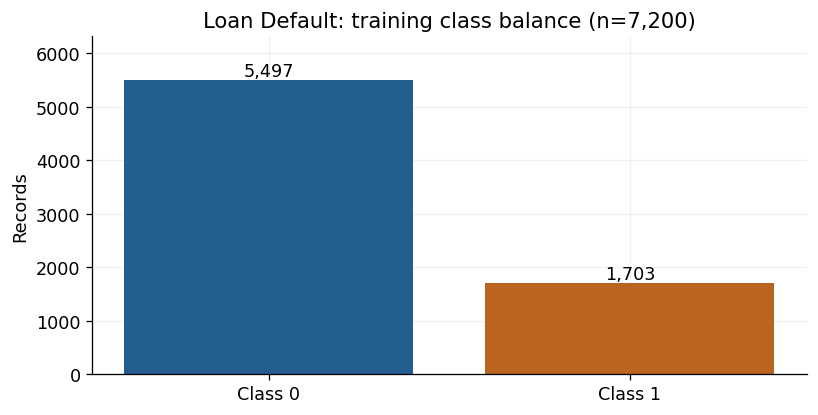

In [4]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### Audit status-linked missingness

The following training-only check demonstrates why seemingly predictive fields are excluded. It is not a candidate model.

In [5]:
audit_fields=['rate_of_interest','Interest_rate_spread','Upfront_charges','property_value','LTV','dtir1']
training_source=source_frame.loc[X_train.index]
audit=training_source.groupby('Status')[audit_fields].agg(lambda s:s.isna().mean()).T
audit.columns=['Missing share, class 0','Missing share, class 1']
display(audit)
artifact_accuracy=accuracy_score(y_train,training_source['rate_of_interest'].isna().astype(int))
display(Markdown(f'**Training-only audit:** the missing-interest-rate rule has {artifact_accuracy:.2%} accuracy. '
    'Pricing, property/LTV/DTI fields, credit_type, and post-outcome fields stay outside all models. '
    'This restricted task classifies recorded status; its undocumented timing prevents a future-default claim.'))

,"Missing share, class 0","Missing share, class 1"
rate_of_interest,0.0000,0.9941
Interest_rate_spread,0.0000,1.0000
Upfront_charges,0.0331,0.9953
property_value,0.0000,0.4116
LTV,0.0000,0.4116
dtir1,0.0773,0.4422


**Training-only audit:** the missing-interest-rate rule has 99.86% accuracy. Pricing, property/LTV/DTI fields, credit_type, and post-outcome fields stay outside all models. This restricted task classifies recorded status; its undocumented timing prevents a future-default claim.

### A3. Tune each model family on training folds

The independent validation set selects among tuned families; test outcomes do not enter selection.

In [6]:
specifications={
    'Decision tree': (DecisionTreeClassifier(random_state=SEED),
        {'model__max_depth':[2,4,8,None], 'model__min_samples_leaf':[1,10], 'model__ccp_alpha':[0,0.001]}),
    'Random forest': (RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=1),
        {'model__max_depth':[4,None], 'model__min_samples_leaf':[1,10], 'model__max_features':['sqrt',1.0]})}
searches={}; rows=[]
for name,(model,grid) in specifications.items():
    searches[name],row=tune(model,grid,scale=False)
    rows.append({'Model':name,**row})
comparison=pd.DataFrame(rows).set_index('Model')
fitted={name:search.best_estimator_ for name,search in searches.items()}
chosen_name=comparison['Validation AUC'].idxmax()
selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Model':name,'Parameter':key.removeprefix('model__'),'Value':str(value)}
    for name,search in searches.items() for key,value in search.best_params_.items()]))
# This unconstrained reference is prespecified and never a candidate selected on test results.
unrestricted=pipeline(DecisionTreeClassifier(random_state=SEED),scale=False).fit(X_train,y_train)
display(pd.DataFrame([{'Tree':label,'Depth':m.named_steps['model'].get_depth(),
    'Leaves':m.named_steps['model'].get_n_leaves(),
    'Train AUC':roc_auc_score(y_train,score_values(m,X_train)),
    'Validation AUC':roc_auc_score(y_valid,score_values(m,X_valid))}
    for label,m in [('Unrestricted reference',unrestricted),('Tuned tree',fitted['Decision tree'])]]))
display(Markdown(f'Validation selected **{chosen_name}**. Depth, leaf size, pruning and feature sampling '
    'are tuned only inside training CV. The forest uses 200 bootstrap trees.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Decision tree,0.6087,0.0078,0.6171,0.5993,0.3443,0.9714
Random forest,0.6366,0.0116,0.8267,0.6445,0.4112,16.8676


,Model,Parameter,Value
0,Decision tree,ccp_alpha,0.001
1,Decision tree,max_depth,8
2,Decision tree,min_samples_leaf,1
3,Random forest,max_depth,None
4,Random forest,max_features,sqrt
5,Random forest,min_samples_leaf,10


,Tree,Depth,Leaves,Train AUC,Validation AUC
0,Unrestricted reference,40,1832,1.0000,0.5415
1,Tuned tree,5,8,0.6171,0.5993


Validation selected **Random forest**. Depth, leaf size, pruning and feature sampling are tuned only inside training CV. The forest uses 200 bootstrap trees.

### A4. Inspect regularization and complexity

Fold-to-fold variation is descriptive, not an independent-experiment confidence interval.

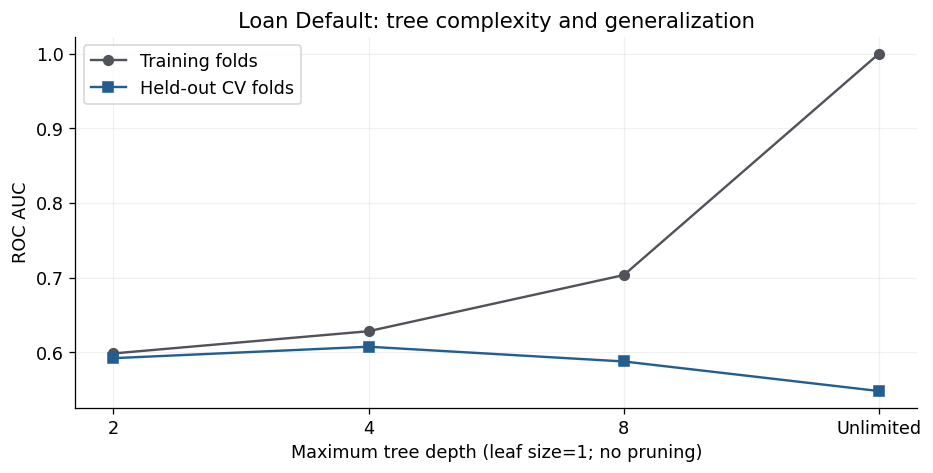

In [7]:
cv=pd.DataFrame(searches['Decision tree'].cv_results_)
curve=cv[(cv['param_model__min_samples_leaf']==1)&(cv['param_model__ccp_alpha']==0)].copy()
curve['depth_label']=curve['param_model__max_depth'].map(lambda v:'Unlimited' if pd.isna(v) else str(int(v)))
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
for field,label,color,marker in [('mean_train_auc','Training folds',GRAY,'o'),('mean_test_auc','Held-out CV folds',BLUE,'s')]:
    ax.plot(curve['depth_label'],curve[field],marker=marker,color=color,label=label)
ax.set(xlabel='Maximum tree depth (leaf size=1; no pruning)',ylabel='ROC AUC',
    title=f'{plot_label}: tree complexity and generalization')
ax.legend();plt.show()

### A5. Read the fitted tree

A truncated display shows interpretable rules; it does not prune the actual estimator. Thresholds use the displayed feature units, including logged amount/income for LendingClub; one-hot thresholds represent categories.

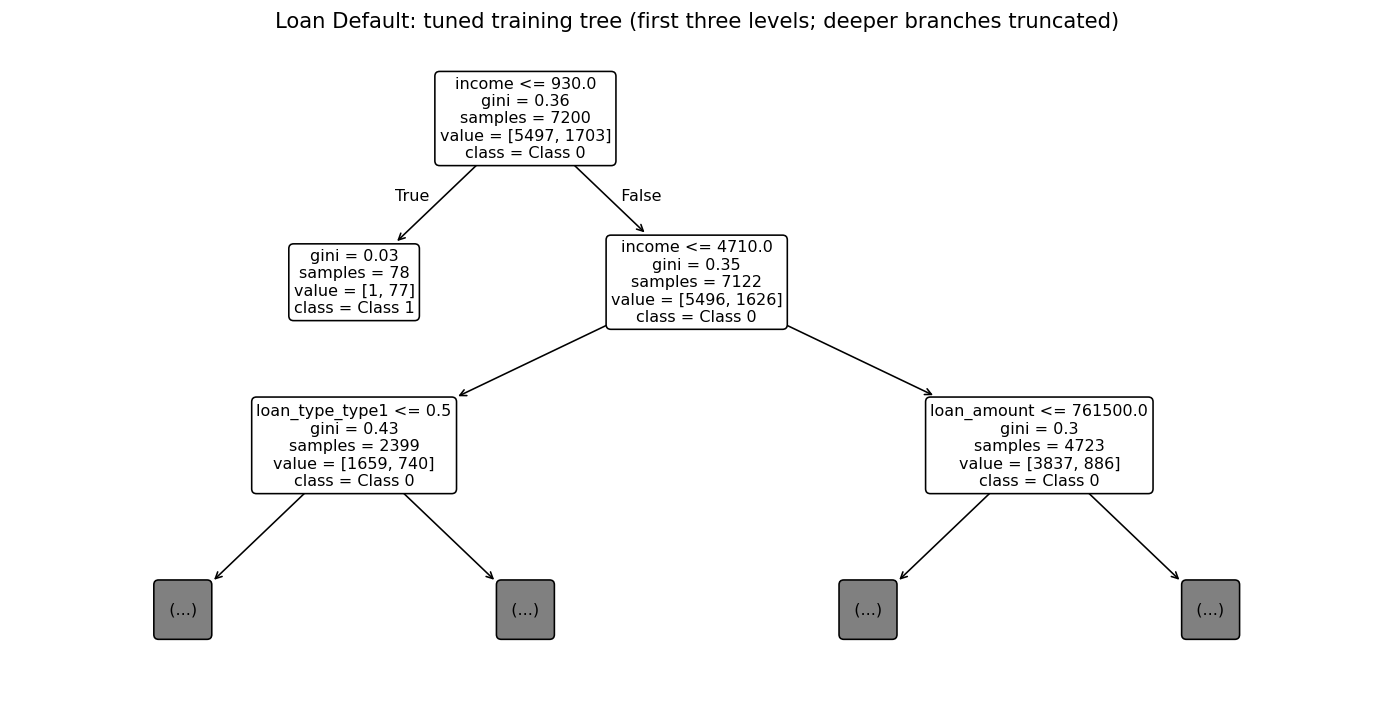

In [8]:
tree=fitted['Decision tree']
fig,ax=plt.subplots(figsize=(12,6),layout='constrained')
plot_tree(tree.named_steps['model'],feature_names=tree.named_steps['prepare'].get_feature_names_out(),
    class_names=['Class 0','Class 1'],max_depth=2,filled=False,rounded=True,precision=2,fontsize=10,ax=ax)
ax.set_title(f'{plot_label}: tuned training tree (first three levels; deeper branches truncated)')
plt.show()

### A6. Inspect held-out forest permutation importance

Shuffling original input columns keeps category indicator blocks together. Validation is used for this diagnostic; test remains reserved.

,Feature,Mean AUC decrease,Repeat SD
1,income,0.0957,0.0091
4,loan_type,0.0271,0.0070
5,loan_purpose,0.0208,0.0060
0,loan_amount,0.0118,0.0070
3,term,0.0108,0.0012
6,occupancy_type,0.0106,0.0027
2,Credit_Score,0.0088,0.0042


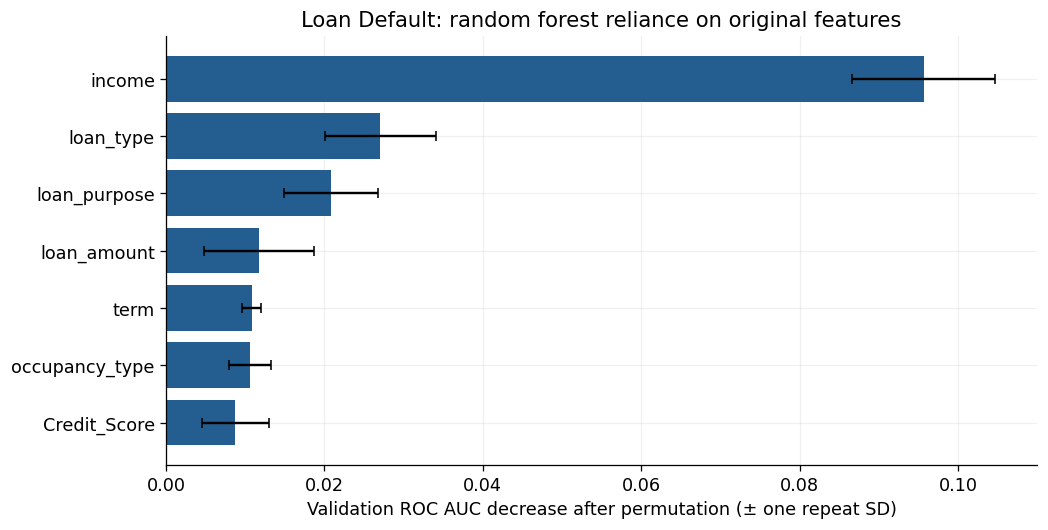

Permutation importance describes this fitted forest on the validation partition; repeat SD is not a confidence interval. Correlated predictors can share importance. Negative values indicate that shuffling helped on this partition. With only seven bank validation records, importance is especially unstable and cannot establish population drivers.

In [9]:
# Permute original columns through the complete pipeline, not individual dummy columns.
forest=fitted['Random forest']
importance=permutation_importance(forest,X_valid,y_valid,scoring='roc_auc',
    n_repeats=10,random_state=SEED,n_jobs=1)
importance_table=pd.DataFrame({'Feature':X.columns,'Mean AUC decrease':importance.importances_mean,
    'Repeat SD':importance.importances_std}).sort_values('Mean AUC decrease')
display(importance_table.sort_values('Mean AUC decrease',ascending=False))
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
ax.barh(importance_table['Feature'],importance_table['Mean AUC decrease'],
    xerr=importance_table['Repeat SD'],color=BLUE,capsize=3)
ax.axvline(0,color=GRAY,linewidth=1)
ax.set(xlabel='Validation ROC AUC decrease after permutation (± one repeat SD)',
    title=f'{plot_label}: random forest reliance on original features')
plt.show()
display(Markdown('Permutation importance describes this fitted forest on the validation partition; '
    'repeat SD is not a confidence interval. Correlated predictors can share importance. '
    'Negative values indicate that shuffling helped on this partition. '
    'With only seven bank validation records, importance is especially unstable and cannot establish population drivers.'))

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range so nearly constant margins remain visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.6445,0.4112,0.7738,0.5354,0.6812,0.0827,0.1476,69
Validation F1,0.6445,0.4112,0.5558,0.6064,0.3079,0.7025,0.4281,1296


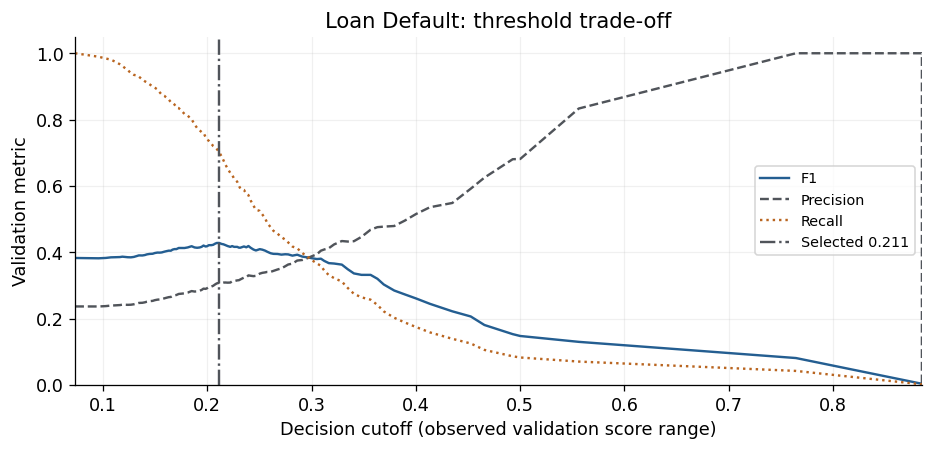

In [10]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.0 if hasattr(selected,'decision_function') else 0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')
ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

In [11]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Model,,,,,,,,
Decision tree,0.5956,0.3271,0.7692,0.5263,0.6167,0.0651,0.1178,60
Random forest,0.6464,0.4001,0.7729,0.5245,0.8108,0.0528,0.0992,37
Logistic baseline,0.5906,0.2968,0.7633,0.5000,0.0000,0.0000,0.0000,0
Prevalence baseline,0.5000,0.2367,0.7633,0.5000,0.0000,0.0000,0.0000,0
Random forest (validation F1 cutoff),0.6464,0.4001,0.5625,0.5932,0.3028,0.6514,0.4134,1222


95% stratified row-bootstrap AUC interval: [0.623, 0.673]
Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

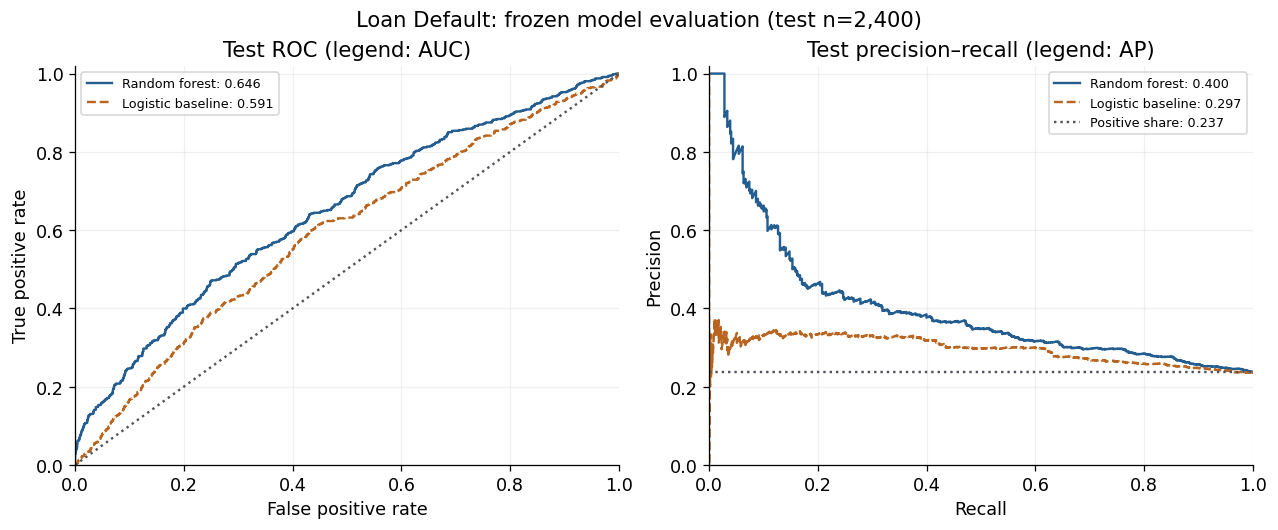

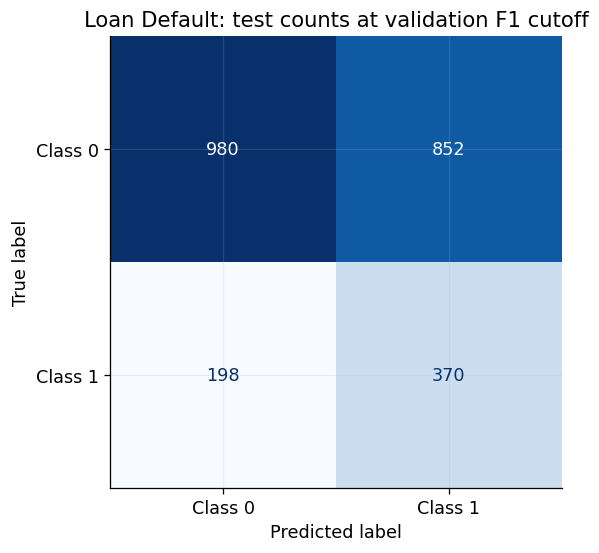

In [12]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [13]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
sv_note = (f"The selected kernel uses C={selected.named_steps['model'].C}; "
    f"{selected.named_steps['model'].n_support_.sum():,}/{len(y_train):,} training records are support vectors. "
    "The kernel comparison and CV penalty path show whether extra flexibility helped within this finite search."
    if hasattr(selected.named_steps['model'],'n_support_') else
    "The unrestricted-tree comparison exposes training optimism; CV complexity curves and held-out forest importance "
    "make the depth/variance trade-off inspectable. A forest is not guaranteed to beat a tuned single tree.")
caveat = ('Only eight bank test records support this estimate. One changed label or prediction can materially change it; '
    'checking status is an account attribute, not a credit-risk outcome.' if groups is not None else
    'These historical random-split results do not establish future-cohort accuracy or borrower independence. '
    'The loan outcome definitions and exclusions limit the population to which this result applies.')
display(Markdown(f'''### Dataset takeaways — {dataset_name}

Validation selected **{chosen_name}**; the frozen model has test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}**, against test positive share **{r['Test positive share']:.3f}**. The prespecified logistic baseline has AUC **{log_auc:.3f}** (descriptive difference **{r['ROC AUC']-log_auc:+.3f}**, not a significance claim).

{sv_note}

The validation-selected operating rule yields test F1 **{r['F1 (validation cutoff)']:.3f}** and confusion counts TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

{caveat} These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.
'''))

### Dataset takeaways — Loan_Default.csv

Validation selected **Random forest**; the frozen model has test ROC AUC **0.646** and average precision **0.400**, against test positive share **0.237**. The prespecified logistic baseline has AUC **0.591** (descriptive difference **+0.056**, not a significance claim).

The unrestricted-tree comparison exposes training optimism; CV complexity curves and held-out forest importance make the depth/variance trade-off inspectable. A forest is not guaranteed to beat a tuned single tree.

The validation-selected operating rule yields test F1 **0.413** and confusion counts TN=980, FP=852, FN=198, TP=370. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

These historical random-split results do not establish future-cohort accuracy or borrower independence. The loan outcome definitions and exclusions limit the population to which this result applies. These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.


**What this dataset teaches.** The unrestricted tree reached training AUC 1.000 but validation AUC only 0.542; the tuned tree had depth 5, eight leaves and validation AUC 0.599. The selected forest's test AUC was 0.646 versus logistic 0.591. Validation permutation importance placed income first. The fitted tree's low-income branch was almost entirely Status 1, which warrants checking collection rules and target timing before calling income a real-world risk driver.

## B. accepted_2007_to_2018Q4.csv — independent analysis

**Outcome:** Charged Off=1 versus Fully Paid=0, conditional on **resolved 2015 36-month loans**. Stream the entire 1.6 GB file and retain a uniform random-priority sample of 12,000 eligible loans. Count all source rows, cohort exclusions and unresolved/other statuses. Use application-era amount, income, FICO, DTI, revolving utilization, open accounts, home ownership, purpose and verification status. Exclude repayments, recoveries, current status, grade and pricing from predictors. No unknown or ongoing loan is labeled fully paid. Historical resolved-only selection and incomplete feature-timing documentation limit prospective interpretation.

### B1. Load and reconcile source data

In [14]:
dataset_name = 'accepted_2007_to_2018Q4.csv'
outcome_label = 'charged off among resolved 2015 36-month loans'
USECOLS = ['id', 'loan_amnt', 'annual_inc', 'fico_range_low', 'fico_range_high',
           'dti', 'revol_util', 'open_acc', 'emp_length', 'earliest_cr_line',
           'issue_d', 'loan_status', 'term', 'home_ownership', 'purpose', 'verification_status']
rng = np.random.default_rng(SEED)
frame = pd.DataFrame()
all_rows = vintage_rows = short_term_rows = eligible_rows = 0
status_counts = pd.Series(dtype='int64')
for chunk in pd.read_csv(DATA_DIR / dataset_name, usecols=USECOLS, chunksize=150_000, low_memory=False):
    all_rows += len(chunk)
    cohort = chunk.loc[chunk['issue_d'].astype('str').str.endswith('2015')].copy()
    vintage_rows += len(cohort)
    cohort = cohort.loc[cohort['term'].str.strip().eq('36 months')]
    short_term_rows += len(cohort)
    status_counts = status_counts.add(cohort['loan_status'].value_counts(), fill_value=0)
    cohort = cohort.loc[cohort['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
    eligible_rows += len(cohort)
    if len(cohort):
        cohort['_priority'] = rng.random(len(cohort))
        frame = pd.concat([frame, cohort.nsmallest(SAMPLE_SIZE, '_priority')]).nsmallest(SAMPLE_SIZE, '_priority')
frame = frame.drop(columns='_priority').reset_index(drop=True)
assert frame['id'].notna().all() and frame['id'].is_unique
display(pd.Series({'source rows': all_rows, '2015 records': vintage_rows,
    '2015 36-month records': short_term_rows, 'resolved eligible records': eligible_rows,
    'excluded unresolved/other statuses': short_term_rows - eligible_rows,
    'uniform sample': len(frame)}, name='Resolved-outcome cohort'))
display(status_counts.astype(int).rename('2015 36-month records').to_frame())
X = pd.DataFrame({
    'log_loan_amount': np.log1p(frame['loan_amnt'].where(frame['loan_amnt'] > 0)),
    'log_annual_income': np.log1p(frame['annual_inc'].where(frame['annual_inc'] >= 0)),
    'fico_mid': (frame['fico_range_low'] + frame['fico_range_high']) / 2,
    'dti': frame['dti'].where(frame['dti'] >= 0),
    'revol_util': frame['revol_util'].where(frame['revol_util'] >= 0),
    'open_acc': frame['open_acc']})
numeric = list(X.columns)
categorical = ['home_ownership', 'purpose', 'verification_status']
for name in categorical:
    X[name] = frame[name].astype(object).where(frame[name].notna(), np.nan)
y = frame['loan_status'].eq('Charged Off').astype(int)
groups = None

source rows                           2260701
2015 records                           421095
2015 36-month records                  283173
resolved eligible records              283026
excluded unresolved/other statuses        147
uniform sample                          12000
Name: Resolved-outcome cohort, dtype: int64

,2015 36-month records
loan_status,
Charged Off,42132
Current,72
Fully Paid,240894
In Grace Period,9
Late (16-30 days),5
Late (31-120 days),61


### B2. Reserve evaluation records and audit training inputs

Only fixed row-wise feature rules precede splitting. Class counts are shown for every partition; learned imputation, encoding and scaling remain within training folds.

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,7200,6193,1007,0.1399,7200
Validation,2400,2064,336,0.1400,2400
Test,2400,2064,336,0.1400,2400


,Training missing (%)
log_loan_amount,0.0000
log_annual_income,0.0000
fico_mid,0.0000
dti,0.0000
revol_util,0.0278
open_acc,0.0000
home_ownership,0.0000
purpose,0.0000
verification_status,0.0000


,log_loan_amount,log_annual_income,fico_mid,dti,revol_util,open_acc
min,6.9088,8.6997,662.0000,0.1000,0.0000,2.0000
median,9.2104,11.0420,687.0000,17.9400,52.3000,11.0000
max,10.4631,14.4033,847.5000,39.9600,132.5000,47.0000


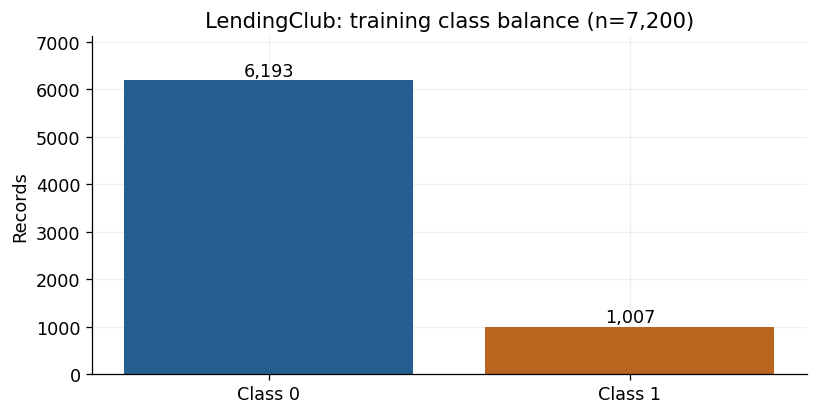

In [15]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### B3. Tune each model family on training folds

The independent validation set selects among tuned families; test outcomes do not enter selection.

In [16]:
specifications={
    'Decision tree': (DecisionTreeClassifier(random_state=SEED),
        {'model__max_depth':[2,4,8,None], 'model__min_samples_leaf':[1,10], 'model__ccp_alpha':[0,0.001]}),
    'Random forest': (RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=1),
        {'model__max_depth':[4,None], 'model__min_samples_leaf':[1,10], 'model__max_features':['sqrt',1.0]})}
searches={}; rows=[]
for name,(model,grid) in specifications.items():
    searches[name],row=tune(model,grid,scale=False)
    rows.append({'Model':name,**row})
comparison=pd.DataFrame(rows).set_index('Model')
fitted={name:search.best_estimator_ for name,search in searches.items()}
chosen_name=comparison['Validation AUC'].idxmax()
selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Model':name,'Parameter':key.removeprefix('model__'),'Value':str(value)}
    for name,search in searches.items() for key,value in search.best_params_.items()]))
# This unconstrained reference is prespecified and never a candidate selected on test results.
unrestricted=pipeline(DecisionTreeClassifier(random_state=SEED),scale=False).fit(X_train,y_train)
display(pd.DataFrame([{'Tree':label,'Depth':m.named_steps['model'].get_depth(),
    'Leaves':m.named_steps['model'].get_n_leaves(),
    'Train AUC':roc_auc_score(y_train,score_values(m,X_train)),
    'Validation AUC':roc_auc_score(y_valid,score_values(m,X_valid))}
    for label,m in [('Unrestricted reference',unrestricted),('Tuned tree',fitted['Decision tree'])]]))
display(Markdown(f'Validation selected **{chosen_name}**. Depth, leaf size, pruning and feature sampling '
    'are tuned only inside training CV. The forest uses 200 bootstrap trees.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Decision tree,0.6111,0.0038,0.6373,0.6001,0.1797,1.2226
Random forest,0.6408,0.0177,0.6903,0.6439,0.2155,24.0728


,Model,Parameter,Value
0,Decision tree,ccp_alpha,0
1,Decision tree,max_depth,4
2,Decision tree,min_samples_leaf,1
3,Random forest,max_depth,4
4,Random forest,max_features,sqrt
5,Random forest,min_samples_leaf,10


,Tree,Depth,Leaves,Train AUC,Validation AUC
0,Unrestricted reference,32,1135,1.0000,0.5041
1,Tuned tree,4,16,0.6373,0.6001


Validation selected **Random forest**. Depth, leaf size, pruning and feature sampling are tuned only inside training CV. The forest uses 200 bootstrap trees.

### B4. Inspect regularization and complexity

Fold-to-fold variation is descriptive, not an independent-experiment confidence interval.

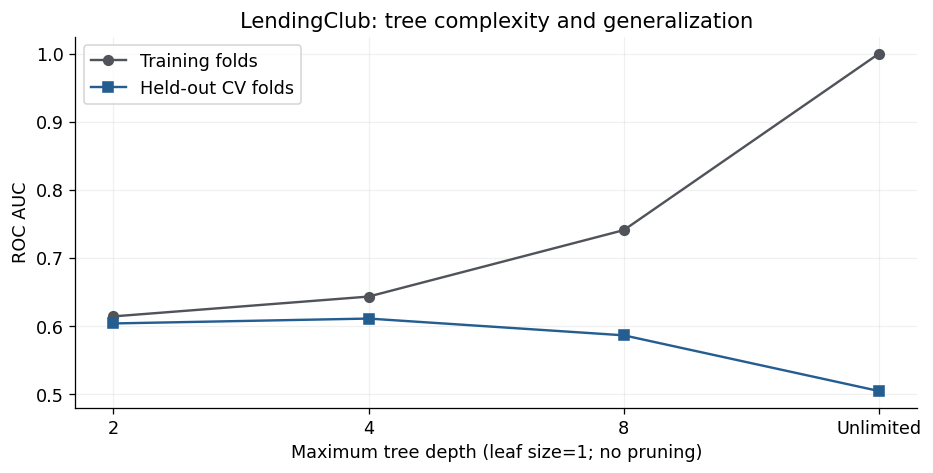

In [17]:
cv=pd.DataFrame(searches['Decision tree'].cv_results_)
curve=cv[(cv['param_model__min_samples_leaf']==1)&(cv['param_model__ccp_alpha']==0)].copy()
curve['depth_label']=curve['param_model__max_depth'].map(lambda v:'Unlimited' if pd.isna(v) else str(int(v)))
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
for field,label,color,marker in [('mean_train_auc','Training folds',GRAY,'o'),('mean_test_auc','Held-out CV folds',BLUE,'s')]:
    ax.plot(curve['depth_label'],curve[field],marker=marker,color=color,label=label)
ax.set(xlabel='Maximum tree depth (leaf size=1; no pruning)',ylabel='ROC AUC',
    title=f'{plot_label}: tree complexity and generalization')
ax.legend();plt.show()

### B5. Read the fitted tree

A truncated display shows interpretable rules; it does not prune the actual estimator. Thresholds use the displayed feature units, including logged amount/income for LendingClub; one-hot thresholds represent categories.

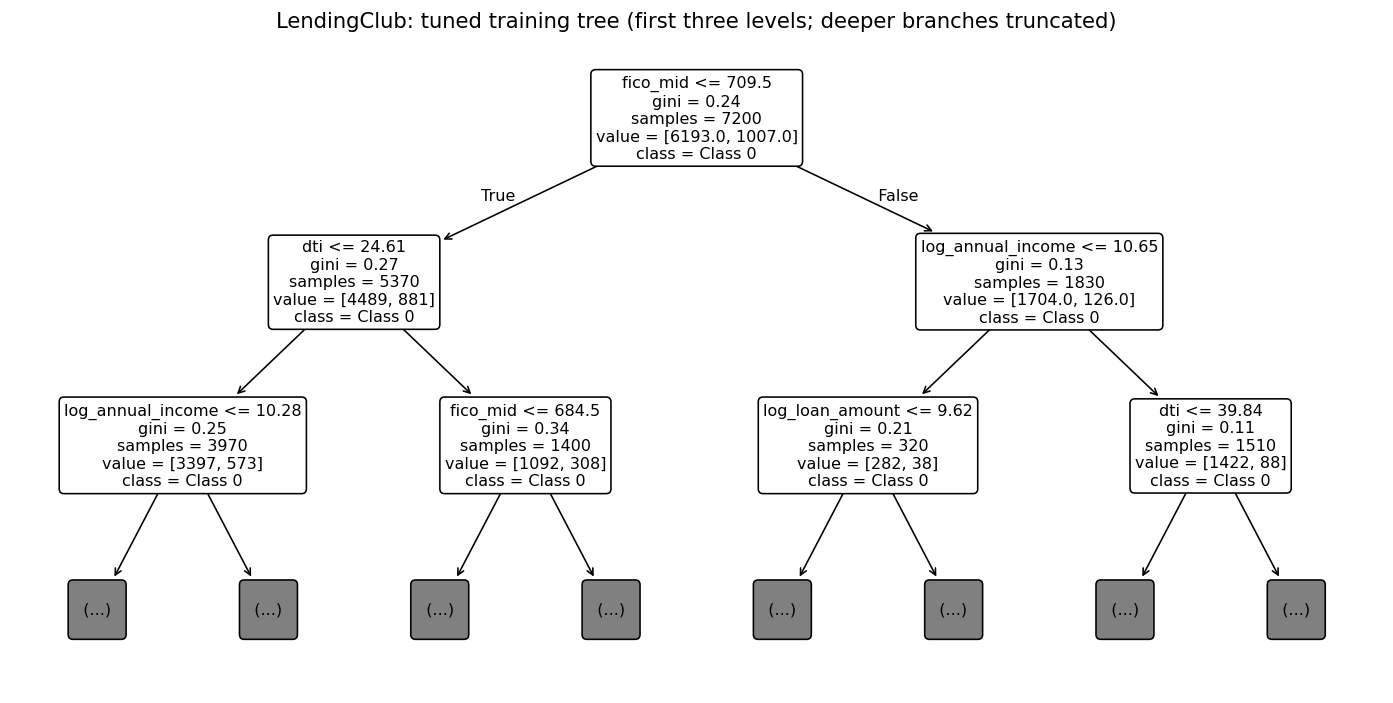

In [18]:
tree=fitted['Decision tree']
fig,ax=plt.subplots(figsize=(12,6),layout='constrained')
plot_tree(tree.named_steps['model'],feature_names=tree.named_steps['prepare'].get_feature_names_out(),
    class_names=['Class 0','Class 1'],max_depth=2,filled=False,rounded=True,precision=2,fontsize=10,ax=ax)
ax.set_title(f'{plot_label}: tuned training tree (first three levels; deeper branches truncated)')
plt.show()

### B6. Inspect held-out forest permutation importance

Shuffling original input columns keeps category indicator blocks together. Validation is used for this diagnostic; test remains reserved.

,Feature,Mean AUC decrease,Repeat SD
2,fico_mid,0.0679,0.0118
3,dti,0.0213,0.0030
8,verification_status,0.0115,0.0054
6,home_ownership,0.0084,0.0038
1,log_annual_income,0.0031,0.0066
5,open_acc,0.0027,0.0021
4,revol_util,0.0014,0.0009
0,log_loan_amount,0.0014,0.0011
7,purpose,0.0008,0.0018


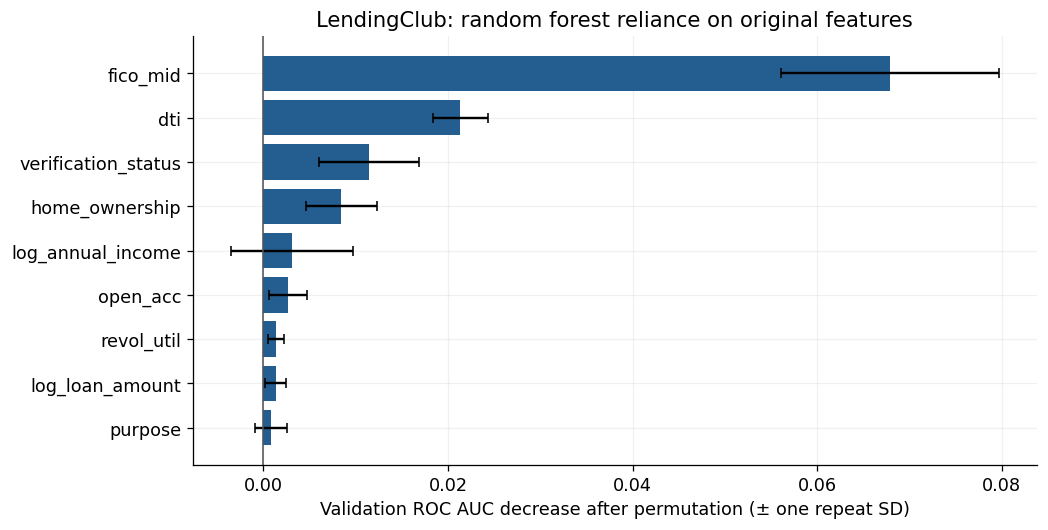

Permutation importance describes this fitted forest on the validation partition; repeat SD is not a confidence interval. Correlated predictors can share importance. Negative values indicate that shuffling helped on this partition. With only seven bank validation records, importance is especially unstable and cannot establish population drivers.

In [19]:
# Permute original columns through the complete pipeline, not individual dummy columns.
forest=fitted['Random forest']
importance=permutation_importance(forest,X_valid,y_valid,scoring='roc_auc',
    n_repeats=10,random_state=SEED,n_jobs=1)
importance_table=pd.DataFrame({'Feature':X.columns,'Mean AUC decrease':importance.importances_mean,
    'Repeat SD':importance.importances_std}).sort_values('Mean AUC decrease')
display(importance_table.sort_values('Mean AUC decrease',ascending=False))
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
ax.barh(importance_table['Feature'],importance_table['Mean AUC decrease'],
    xerr=importance_table['Repeat SD'],color=BLUE,capsize=3)
ax.axvline(0,color=GRAY,linewidth=1)
ax.set(xlabel='Validation ROC AUC decrease after permutation (± one repeat SD)',
    title=f'{plot_label}: random forest reliance on original features')
plt.show()
display(Markdown('Permutation importance describes this fitted forest on the validation partition; '
    'repeat SD is not a confidence interval. Correlated predictors can share importance. '
    'Negative values indicate that shuffling helped on this partition. '
    'With only seven bank validation records, importance is especially unstable and cannot establish population drivers.'))

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range so nearly constant margins remain visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.6439,0.2155,0.8600,0.5000,0.0000,0.0000,0.0000,0
Validation F1,0.6439,0.2155,0.5525,0.6090,0.1925,0.6875,0.3008,1200


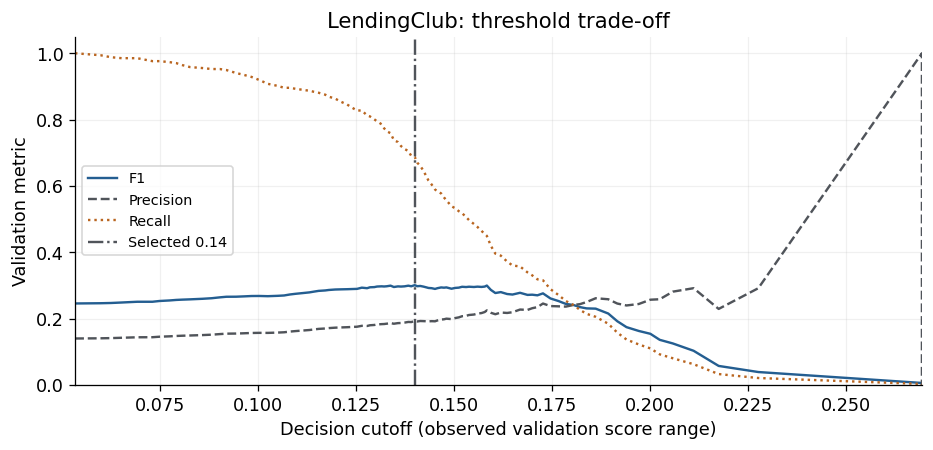

In [20]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.0 if hasattr(selected,'decision_function') else 0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')
ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

In [21]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Model,,,,,,,,
Decision tree,0.5907,0.1772,0.8583,0.4990,0.0000,0.0000,0.0000,4
Random forest,0.6330,0.2209,0.8600,0.5000,0.0000,0.0000,0.0000,0
Logistic baseline,0.6333,0.2087,0.8600,0.5000,0.0000,0.0000,0.0000,0
Prevalence baseline,0.5000,0.1400,0.8600,0.5000,0.0000,0.0000,0.0000,0
Random forest (validation F1 cutoff),0.6330,0.2209,0.5421,0.5818,0.1797,0.6369,0.2803,1191


95% stratified row-bootstrap AUC interval: [0.601, 0.662]
Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

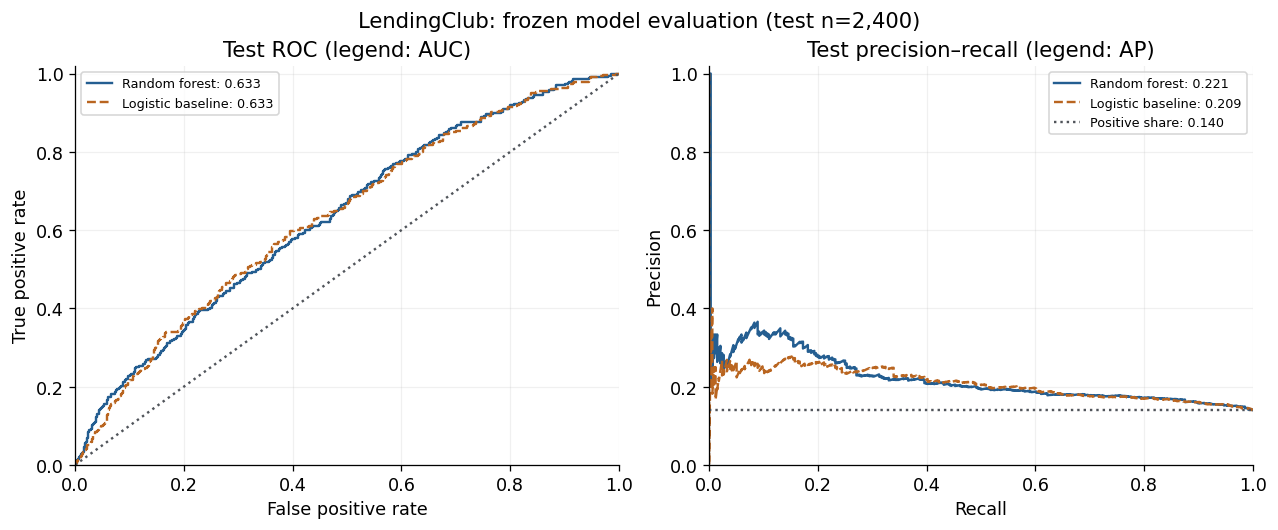

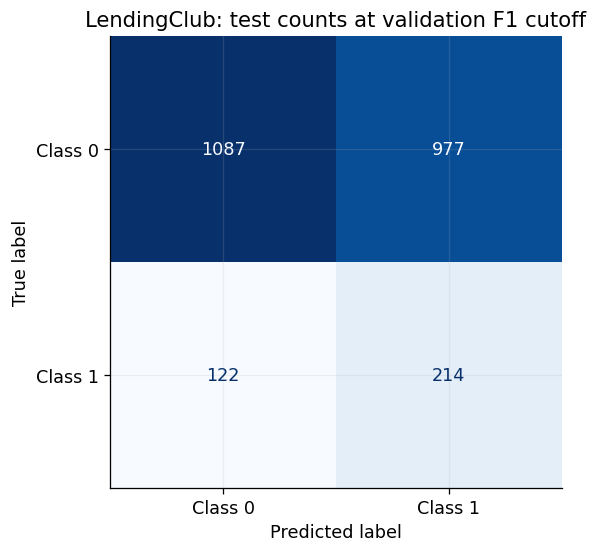

In [22]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [23]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
sv_note = (f"The selected kernel uses C={selected.named_steps['model'].C}; "
    f"{selected.named_steps['model'].n_support_.sum():,}/{len(y_train):,} training records are support vectors. "
    "The kernel comparison and CV penalty path show whether extra flexibility helped within this finite search."
    if hasattr(selected.named_steps['model'],'n_support_') else
    "The unrestricted-tree comparison exposes training optimism; CV complexity curves and held-out forest importance "
    "make the depth/variance trade-off inspectable. A forest is not guaranteed to beat a tuned single tree.")
caveat = ('Only eight bank test records support this estimate. One changed label or prediction can materially change it; '
    'checking status is an account attribute, not a credit-risk outcome.' if groups is not None else
    'These historical random-split results do not establish future-cohort accuracy or borrower independence. '
    'The loan outcome definitions and exclusions limit the population to which this result applies.')
display(Markdown(f'''### Dataset takeaways — {dataset_name}

Validation selected **{chosen_name}**; the frozen model has test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}**, against test positive share **{r['Test positive share']:.3f}**. The prespecified logistic baseline has AUC **{log_auc:.3f}** (descriptive difference **{r['ROC AUC']-log_auc:+.3f}**, not a significance claim).

{sv_note}

The validation-selected operating rule yields test F1 **{r['F1 (validation cutoff)']:.3f}** and confusion counts TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

{caveat} These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.
'''))

### Dataset takeaways — accepted_2007_to_2018Q4.csv

Validation selected **Random forest**; the frozen model has test ROC AUC **0.633** and average precision **0.221**, against test positive share **0.140**. The prespecified logistic baseline has AUC **0.633** (descriptive difference **-0.000**, not a significance claim).

The unrestricted-tree comparison exposes training optimism; CV complexity curves and held-out forest importance make the depth/variance trade-off inspectable. A forest is not guaranteed to beat a tuned single tree.

The validation-selected operating rule yields test F1 **0.280** and confusion counts TN=1087, FP=977, FN=122, TP=214. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

These historical random-split results do not establish future-cohort accuracy or borrower independence. The loan outcome definitions and exclusions limit the population to which this result applies. These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.


**What this dataset teaches.** An unrestricted tree reached training AUC 1.000 and validation AUC 0.504. Restricting the tuned tree to depth 4 raised validation AUC to 0.600, while the forest reached 0.644 on validation. On test the selected forest and logistic baseline both rounded to AUC 0.633; greater flexibility did not establish a test ranking advantage. FICO was the strongest validation permutation feature for this forest, a statement about model reliance rather than a causal credit effect.

## C. bank_customers.csv — independent analysis

**Outcome:** checking=1 versus savings/CD=0, derived from AccountType. Use only age and historical tenure as predictors; exclude AccountType itself. This file supplies **no loan-default label**, so this is an account-type classification demonstration. Keep prior date eligibility rules and group repeated AccountID values conservatively. Read no SSNs and display no personal identifiers. Explicitly report the 100-row source audit and 39-row eligible population.

### C1. Load and reconcile source data

In [24]:
dataset_name = 'bank_customers.csv'
source_frame = pd.read_csv(DATA_DIR / dataset_name, usecols=lambda name: name != 'SSN')
AS_OF = pd.Timestamp('2026-09-26')
birth_text = source_frame['BirthDate'].astype('string').str.strip()
partial_birth = birth_text.str.fullmatch(r'\d{4}', na=False)
birth = pd.to_datetime(birth_text.mask(partial_birth), format='mixed', errors='coerce')
opened = pd.to_datetime(source_frame['AccountOpened'], format='mixed', errors='coerce')
valid_type = source_frame['AccountType'].isin(['checking', 'savings', 'cd'])
eligible = (birth.notna() & opened.notna() & birth.le(AS_OF) & opened.le(AS_OF)
            & opened.ge(birth) & valid_type)
# Reason flags overlap; the union, not their sum, determines exclusions.
display(pd.Series({'source records': len(source_frame),
    'missing/invalid/partial birth date': birth.isna().sum(),
    'missing/invalid opening date': opened.isna().sum(),
    'future opening date': opened.gt(AS_OF).sum(),
    'opening before exact birth date': opened.lt(birth).sum(),
    'missing/unrecognized account type': (~valid_type).sum(),
    'eligible records': eligible.sum(), 'excluded union': (~eligible).sum()}, name='Bank eligibility audit'))
frame = source_frame.loc[eligible].copy()
frame['age_years'] = (AS_OF - birth.loc[eligible]).dt.days / 365.25
frame['tenure_years'] = (AS_OF - opened.loc[eligible]).dt.days / 365.25
# Repeated AccountID values are conservatively grouped, even though this file
# does not document whether they represent shared accounts or data-quality issues.
frame['_group'] = frame['AccountID'].astype('string')
frame['_group'] = frame['_group'].fillna(pd.Series(
    ['missing_account_' + str(i) for i in frame.index], index=frame.index))
frame = frame.reset_index(drop=True)
groups = frame['_group']
assert len(frame) >= 20
display(frame['AccountType'].value_counts().rename('eligible records').to_frame())
# BirthDate, CustomerID, AccountID, and SSN are never displayed or used as model features.

outcome_label = 'checking account versus savings/CD'
X = frame[['age_years', 'tenure_years']].copy()
y = frame['AccountType'].eq('checking').astype(int)
numeric, categorical = list(X.columns), []

source records                        100
missing/invalid/partial birth date      3
missing/invalid opening date            1
future opening date                    59
opening before exact birth date         0
missing/unrecognized account type       1
eligible records                       39
excluded union                         61
Name: Bank eligibility audit, dtype: int64

,eligible records
AccountType,
checking,16
savings,15
cd,8


### C2. Reserve evaluation records and audit training inputs

Only fixed row-wise feature rules precede splitting. Class counts are shown for every partition; learned imputation, encoding and scaling remain within training folds.

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,24,16,8,0.3333,21
Validation,7,5,2,0.2857,7
Test,8,2,6,0.7500,8


,Training missing (%)
age_years,0.0000
tenure_years,0.0000


,age_years,tenure_years
min,18.5736,1.3990
median,55.2005,23.3566
max,74.6667,64.1396


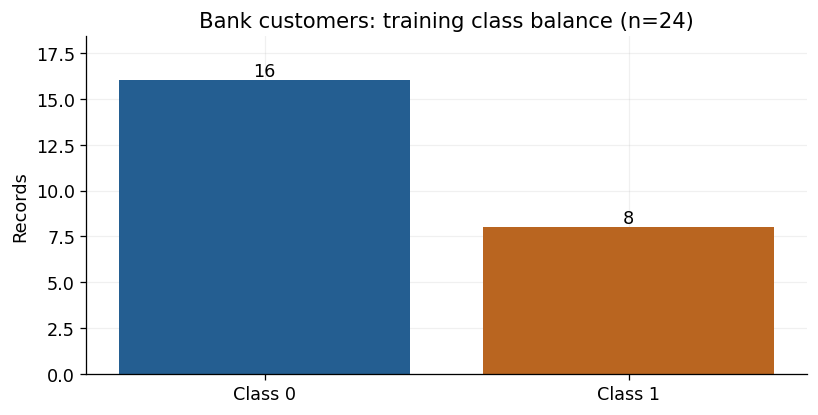

In [25]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### C3. Tune each model family on training folds

The independent validation set selects among tuned families; test outcomes do not enter selection.

In [26]:
specifications={
    'Decision tree': (DecisionTreeClassifier(random_state=SEED),
        {'model__max_depth':[2,4,8,None], 'model__min_samples_leaf':[1,10], 'model__ccp_alpha':[0,0.001]}),
    'Random forest': (RandomForestClassifier(n_estimators=200,random_state=SEED,n_jobs=1),
        {'model__max_depth':[4,None], 'model__min_samples_leaf':[1,10], 'model__max_features':['sqrt',1.0]})}
searches={}; rows=[]
for name,(model,grid) in specifications.items():
    searches[name],row=tune(model,grid,scale=False)
    rows.append({'Model':name,**row})
comparison=pd.DataFrame(rows).set_index('Model')
fitted={name:search.best_estimator_ for name,search in searches.items()}
chosen_name=comparison['Validation AUC'].idxmax()
selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Model':name,'Parameter':key.removeprefix('model__'),'Value':str(value)}
    for name,search in searches.items() for key,value in search.best_params_.items()]))
# This unconstrained reference is prespecified and never a candidate selected on test results.
unrestricted=pipeline(DecisionTreeClassifier(random_state=SEED),scale=False).fit(X_train,y_train)
display(pd.DataFrame([{'Tree':label,'Depth':m.named_steps['model'].get_depth(),
    'Leaves':m.named_steps['model'].get_n_leaves(),
    'Train AUC':roc_auc_score(y_train,score_values(m,X_train)),
    'Validation AUC':roc_auc_score(y_valid,score_values(m,X_valid))}
    for label,m in [('Unrestricted reference',unrestricted),('Tuned tree',fitted['Decision tree'])]]))
display(Markdown(f'Validation selected **{chosen_name}**. Depth, leaf size, pruning and feature sampling '
    'are tuned only inside training CV. The forest uses 200 bootstrap trees.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Decision tree,0.5972,0.2051,0.9219,0.6000,0.3333,0.2256
Random forest,0.5278,0.3087,1.0000,0.7000,0.5000,1.8756


,Model,Parameter,Value
0,Decision tree,ccp_alpha,0
1,Decision tree,max_depth,4
2,Decision tree,min_samples_leaf,1
3,Random forest,max_depth,4
4,Random forest,max_features,1.0
5,Random forest,min_samples_leaf,1


,Tree,Depth,Leaves,Train AUC,Validation AUC
0,Unrestricted reference,8,9,1.0000,0.6000
1,Tuned tree,4,5,0.9219,0.6000


Validation selected **Random forest**. Depth, leaf size, pruning and feature sampling are tuned only inside training CV. The forest uses 200 bootstrap trees.

### C4. Inspect regularization and complexity

Fold-to-fold variation is descriptive, not an independent-experiment confidence interval.

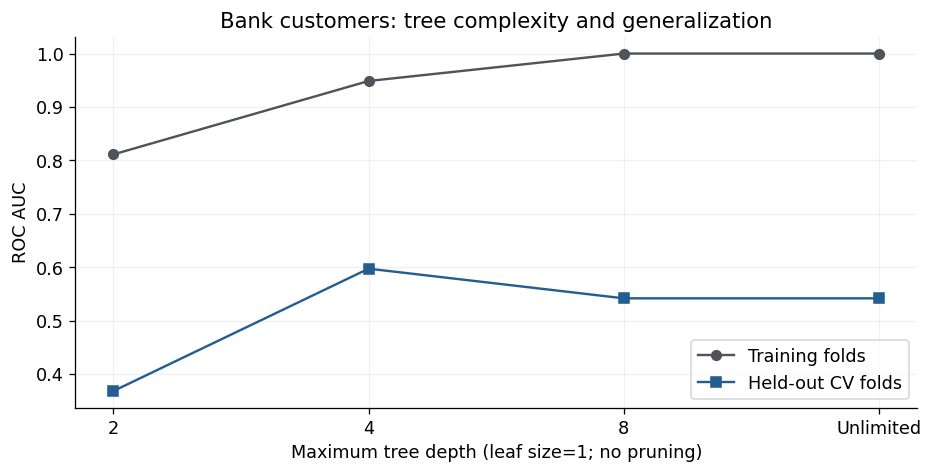

In [27]:
cv=pd.DataFrame(searches['Decision tree'].cv_results_)
curve=cv[(cv['param_model__min_samples_leaf']==1)&(cv['param_model__ccp_alpha']==0)].copy()
curve['depth_label']=curve['param_model__max_depth'].map(lambda v:'Unlimited' if pd.isna(v) else str(int(v)))
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
for field,label,color,marker in [('mean_train_auc','Training folds',GRAY,'o'),('mean_test_auc','Held-out CV folds',BLUE,'s')]:
    ax.plot(curve['depth_label'],curve[field],marker=marker,color=color,label=label)
ax.set(xlabel='Maximum tree depth (leaf size=1; no pruning)',ylabel='ROC AUC',
    title=f'{plot_label}: tree complexity and generalization')
ax.legend();plt.show()

### C5. Read the fitted tree

A truncated display shows interpretable rules; it does not prune the actual estimator. Thresholds use the displayed feature units, including logged amount/income for LendingClub; one-hot thresholds represent categories.

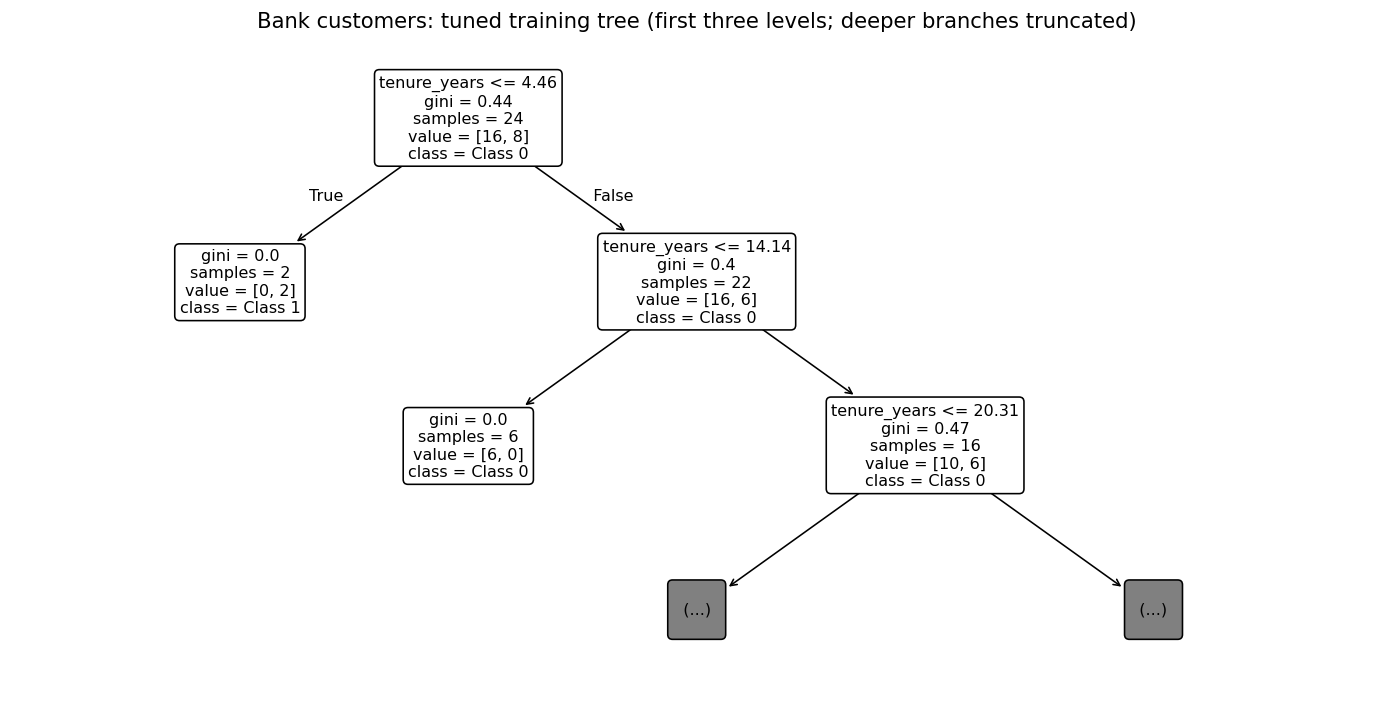

In [28]:
tree=fitted['Decision tree']
fig,ax=plt.subplots(figsize=(12,6),layout='constrained')
plot_tree(tree.named_steps['model'],feature_names=tree.named_steps['prepare'].get_feature_names_out(),
    class_names=['Class 0','Class 1'],max_depth=2,filled=False,rounded=True,precision=2,fontsize=10,ax=ax)
ax.set_title(f'{plot_label}: tuned training tree (first three levels; deeper branches truncated)')
plt.show()

### C6. Inspect held-out forest permutation importance

Shuffling original input columns keeps category indicator blocks together. Validation is used for this diagnostic; test remains reserved.

,Feature,Mean AUC decrease,Repeat SD
1,tenure_years,0.2900,0.2256
0,age_years,0.0900,0.1136


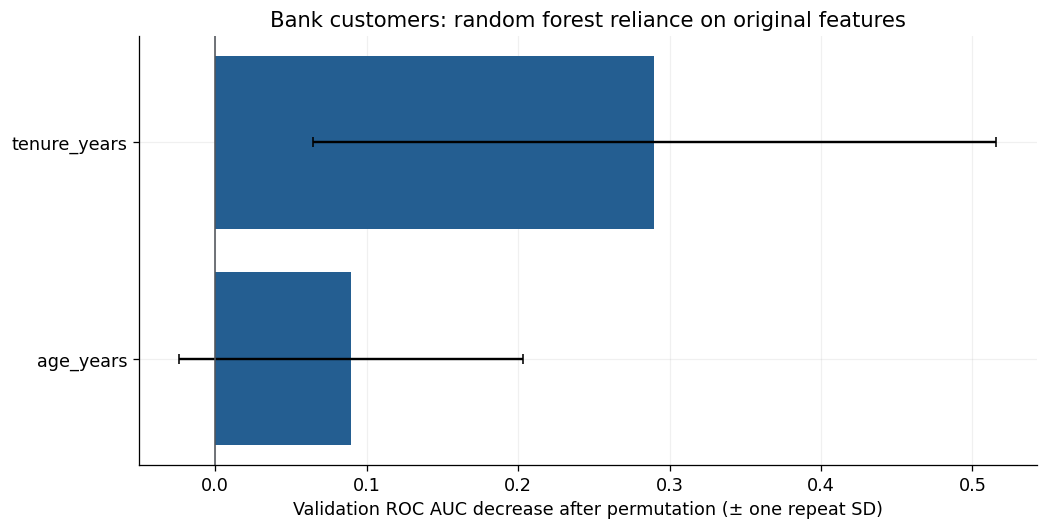

Permutation importance describes this fitted forest on the validation partition; repeat SD is not a confidence interval. Correlated predictors can share importance. Negative values indicate that shuffling helped on this partition. With only seven bank validation records, importance is especially unstable and cannot establish population drivers.

In [29]:
# Permute original columns through the complete pipeline, not individual dummy columns.
forest=fitted['Random forest']
importance=permutation_importance(forest,X_valid,y_valid,scoring='roc_auc',
    n_repeats=10,random_state=SEED,n_jobs=1)
importance_table=pd.DataFrame({'Feature':X.columns,'Mean AUC decrease':importance.importances_mean,
    'Repeat SD':importance.importances_std}).sort_values('Mean AUC decrease')
display(importance_table.sort_values('Mean AUC decrease',ascending=False))
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
ax.barh(importance_table['Feature'],importance_table['Mean AUC decrease'],
    xerr=importance_table['Repeat SD'],color=BLUE,capsize=3)
ax.axvline(0,color=GRAY,linewidth=1)
ax.set(xlabel='Validation ROC AUC decrease after permutation (± one repeat SD)',
    title=f'{plot_label}: random forest reliance on original features')
plt.show()
display(Markdown('Permutation importance describes this fitted forest on the validation partition; '
    'repeat SD is not a confidence interval. Correlated predictors can share importance. '
    'Negative values indicate that shuffling helped on this partition. '
    'With only seven bank validation records, importance is especially unstable and cannot establish population drivers.'))

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range so nearly constant margins remain visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.7000,0.5000,0.5714,0.7000,0.4000,1.0000,0.5714,5
Validation F1,0.7000,0.5000,0.7143,0.8000,0.5000,1.0000,0.6667,4


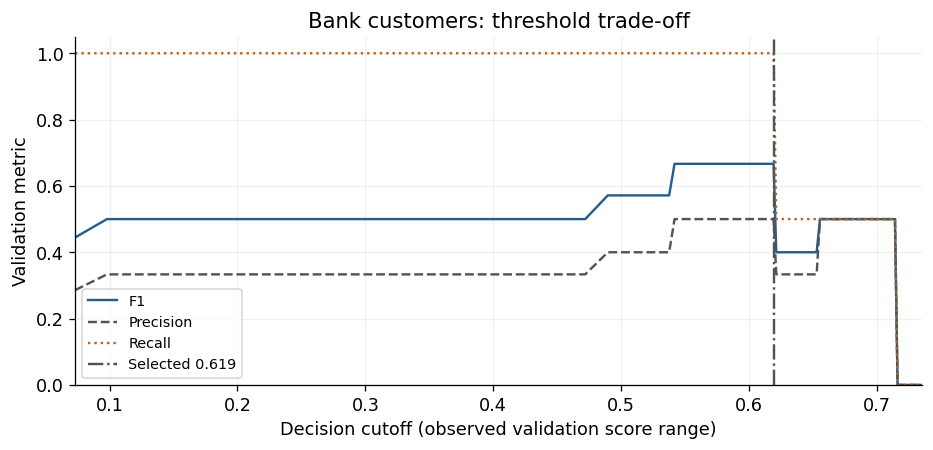

In [30]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.0 if hasattr(selected,'decision_function') else 0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')
ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

In [31]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Model,,,,,,,,
Decision tree,0.3333,0.6944,0.3750,0.4167,0.6667,0.3333,0.4444,3
Random forest,0.4167,0.8135,0.3750,0.4167,0.6667,0.3333,0.4444,3
Logistic baseline,0.5833,0.8179,0.2500,0.5000,0.0000,0.0000,0.0000,0
Prevalence baseline,0.5000,0.7500,0.2500,0.5000,0.0000,0.0000,0.0000,0
Random forest (validation F1 cutoff),0.4167,0.8135,0.3750,0.4167,0.6667,0.3333,0.4444,3


Bank test set: exact confusion counts are primary; no reliable population interval is claimed.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

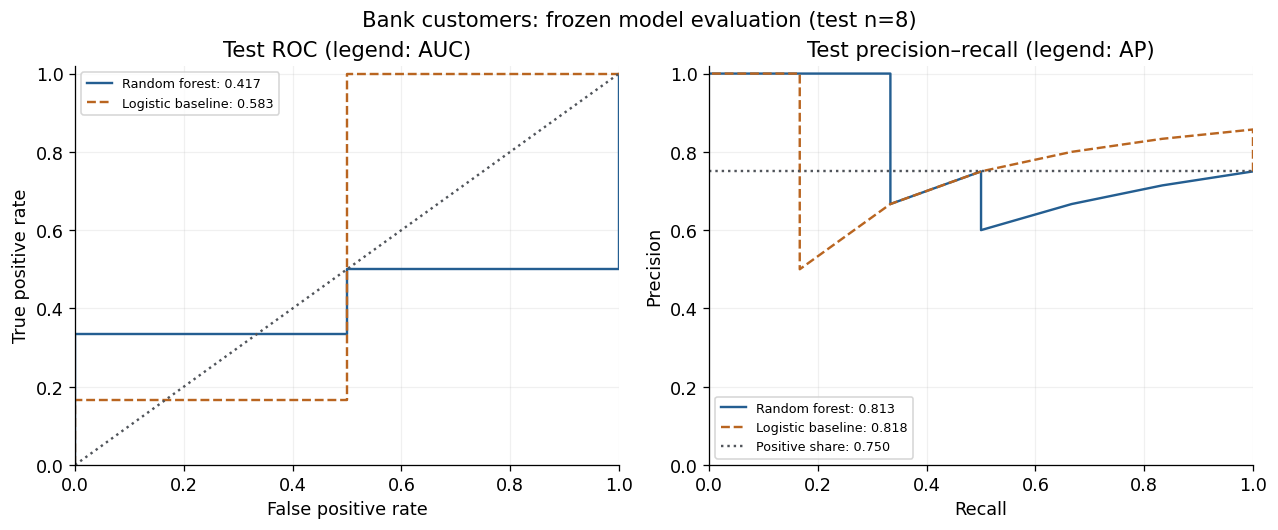

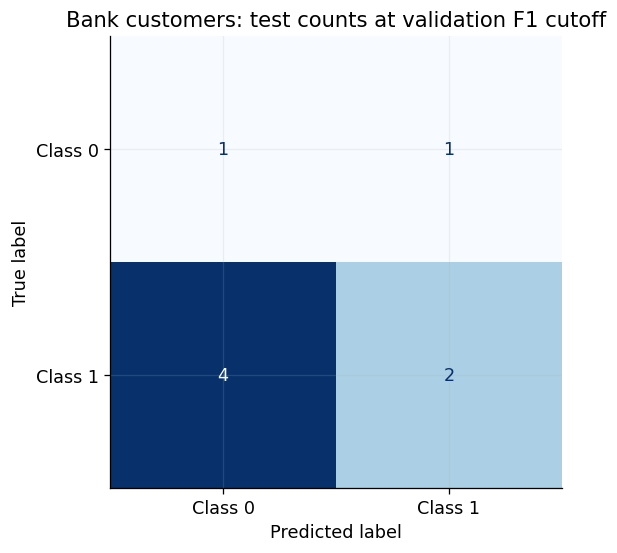

In [32]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [33]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
sv_note = (f"The selected kernel uses C={selected.named_steps['model'].C}; "
    f"{selected.named_steps['model'].n_support_.sum():,}/{len(y_train):,} training records are support vectors. "
    "The kernel comparison and CV penalty path show whether extra flexibility helped within this finite search."
    if hasattr(selected.named_steps['model'],'n_support_') else
    "The unrestricted-tree comparison exposes training optimism; CV complexity curves and held-out forest importance "
    "make the depth/variance trade-off inspectable. A forest is not guaranteed to beat a tuned single tree.")
caveat = ('Only eight bank test records support this estimate. One changed label or prediction can materially change it; '
    'checking status is an account attribute, not a credit-risk outcome.' if groups is not None else
    'These historical random-split results do not establish future-cohort accuracy or borrower independence. '
    'The loan outcome definitions and exclusions limit the population to which this result applies.')
display(Markdown(f'''### Dataset takeaways — {dataset_name}

Validation selected **{chosen_name}**; the frozen model has test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}**, against test positive share **{r['Test positive share']:.3f}**. The prespecified logistic baseline has AUC **{log_auc:.3f}** (descriptive difference **{r['ROC AUC']-log_auc:+.3f}**, not a significance claim).

{sv_note}

The validation-selected operating rule yields test F1 **{r['F1 (validation cutoff)']:.3f}** and confusion counts TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

{caveat} These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.
'''))

### Dataset takeaways — bank_customers.csv

Validation selected **Random forest**; the frozen model has test ROC AUC **0.417** and average precision **0.813**, against test positive share **0.750**. The prespecified logistic baseline has AUC **0.583** (descriptive difference **-0.167**, not a significance claim).

The unrestricted-tree comparison exposes training optimism; CV complexity curves and held-out forest importance make the depth/variance trade-off inspectable. A forest is not guaranteed to beat a tuned single tree.

The validation-selected operating rule yields test F1 **0.444** and confusion counts TN=1, FP=1, FN=4, TP=2. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

Only eight bank test records support this estimate. One changed label or prediction can materially change it; checking status is an account attribute, not a credit-risk outcome. These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.


**What this dataset teaches.** The selected forest had validation AUC 0.700 but test AUC 0.417. Its training AUC was 1.000. With only seven validation and eight test records, this reversal illustrates selection instability rather than evidence that forests systematically fail. The test positive share was 75%, so AP 0.813 should be read against a high prevalence baseline, not interpreted as 81.3% accuracy.

## Results across all three datasets

Targets have different meanings. Compare models **within** a dataset; do not rank the datasets’ difficulty or business value by AUC.

In [34]:
all_results=pd.DataFrame(results).set_index('Dataset')
assert set(all_results.index)=={'Loan_Default.csv','accepted_2007_to_2018Q4.csv','bank_customers.csv'}
assert len(all_results)==3
display(all_results)
for row in results:
    display(Markdown(f"- **{row['Dataset']}** — {row['Outcome']}: **{row['Selected']}**, test AUC **{row['ROC AUC']:.3f}**, AP **{row['Average precision']:.3f}**, F1 at the validation cutoff **{row['F1 (validation cutoff)']:.3f}**, test n={row['Test n']:,}."))

,Outcome,Selected,Train n,Validation n,Test n,ROC AUC,Average precision,Test positive share,F1 (validation cutoff),Cutoff
Dataset,,,,,,,,,,
Loan_Default.csv,recorded Status 1,Random forest,7200,2400,2400,0.6464,0.4001,0.2367,0.4134,0.2113
accepted_2007_to_2018Q4.csv,charged off among resolved 2015 36-month loans,Random forest,7200,2400,2400,0.6330,0.2209,0.1400,0.2803,0.1401
bank_customers.csv,checking account versus savings/CD,Random forest,24,7,8,0.4167,0.8135,0.7500,0.4444,0.6193


- **Loan_Default.csv** — recorded Status 1: **Random forest**, test AUC **0.646**, AP **0.400**, F1 at the validation cutoff **0.413**, test n=2,400.

- **accepted_2007_to_2018Q4.csv** — charged off among resolved 2015 36-month loans: **Random forest**, test AUC **0.633**, AP **0.221**, F1 at the validation cutoff **0.280**, test n=2,400.

- **bank_customers.csv** — checking account versus savings/CD: **Random forest**, test AUC **0.417**, AP **0.813**, F1 at the validation cutoff **0.444**, test n=8.

## Takeaways and Milestone One connection

The selected models answer three separate classification questions. Preserve the target definitions, cohorts, leakage audit, excluded records and sample sizes when compiling Milestone One. Use the saved test tables, complexity diagnostics and confusion counts as evidence; avoid choosing a new model because it looks best on a test chart.

The next useful validation would use a future lending vintage with known feature availability and mature outcomes, verify borrower/account identity, evaluate subgroup performance where appropriate data and sample sizes permit, and choose a cutoff using explicit decision costs. Loan_Default needs documented status timing. Bank modeling needs substantially more valid records and a target aligned with a real decision. These are proposed next steps, not completed validation.

No external data were added. Data provenance is the three local CSV paths and the explicit cohort/sampling audit above. The notebooks document observed historical associations rather than causal effects.

**F1 reasonableness check.** An always-positive rule has precision equal to positive share $p$, recall 1, and $F_1=2p/(1+p)$ (Loan_Default 0.383, LendingClub 0.246, bank 0.857). These are descriptive references derived from the test class counts, not newly trained or selected models. The selected forest cutoff exceeds this reference for Loan_Default (0.413), but the bank forest cutoff falls well below it (0.444). LendingClub F1 is 0.280 versus 0.246 for always positive. Higher F1 alone does not specify business value or acceptable false-positive cost.

## Method references

Implementation is based on the installed scikit-learn **1.8.0** behavior, with versioned primary documentation:

- [Support vector machines: margins, kernels and C](https://scikit-learn.org/1.8/modules/svm.html)
- [Decision trees: impurity, complexity and pruning](https://scikit-learn.org/1.8/modules/tree.html)
- [Random forests and randomized ensembles](https://scikit-learn.org/1.8/modules/ensemble.html#forest)
- [Permutation importance and its limitations](https://scikit-learn.org/1.8/modules/permutation_importance.html)

The supplied assignment mentions a Milestone One rubric link but does not include it. Alignment here is to the supplied Week 5 and Week 6 instructions and prior notebook conventions.